# Radar de Carreiras: análise ampliada 2025–2026
Revisão pública das etapas 03–05. Cada base mantém sua população e período. As perguntas P9–P12 da pesquisa própria permanecem na análise original e na aba CESAR School.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

dashboard = Path.cwd().parent / '06_dashboard_e_publicacao'
sys.path.insert(0, str(dashboard))
from dados import load_expansion
p = load_expansion(dashboard / 'dados_ampliados')
colors = ['#D25E00', '#303843', '#6D7B62']
assert p['metadata']['fontes']['caged_ti']['n'] == p['eda_movimentacoes'].movimentacoes.sum()

## P1–P3. Emprego formal em TI
A série cobre 21 competências. Os períodos comparáveis são janeiro a setembro de ambos os anos. O intervalo p10–p90 não é mínimo–máximo; admissões e saídas não acompanham as mesmas pessoas.

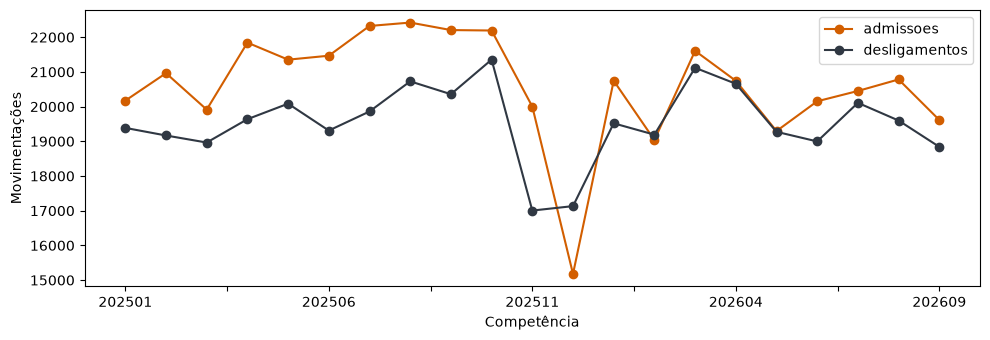

,ano,recorte,movimentacoes,admissoes,desligamentos,salario_mediano_admissoes
0,2025,Brasil,370147,192657,177490,3938.21
1,2025,Pernambuco,7524,4141,3383,3170.42
2,2026,Brasil,359725,182425,177300,3840.89
3,2026,Pernambuco,8953,5016,3937,2983.97


,geo,admissoes_validos,admissoes_p10,admissoes_p50,admissoes_p90,desligamentos_validos,desligamentos_p10,desligamentos_p50,desligamentos_p90
0,BR,431403,1734.05,3934.67,13598.46,408603,1842.41,4418.55,14254.34
988,NE,40220,1526.12,2400.55,8860.97,35719,1533.71,2592.34,8884.39
16796,UF_PE,10743,1579.93,3135.24,9906.88,8387,1611.64,3443.18,10100.14


In [2]:
month = p['eda_movimentacoes'].set_index('competencia')
ax = month[['admissoes', 'desligamentos']].plot(figsize=(10, 3.5), color=colors[:2], marker='o')
ax.set(ylabel='Movimentações', xlabel='Competência')
plt.tight_layout()
plt.show()
display(p['eda_comparacao_anos'].round(2))
c = p['emprego']
display(c.loc[c.geo.isin(['BR','NE','UF_PE']) & c.periodo.eq('todos') & c.tipo.eq('total'),
    ['geo','admissoes_validos','admissoes_p10','admissoes_p50','admissoes_p90',
     'desligamentos_validos','desligamentos_p10','desligamentos_p50','desligamentos_p90']].round(2))

## P4. Salário, escolaridade, idade, jornada e ocupação
As faixas descrevem relações marginais. Não controlam a composição dos cargos, a senioridade ou diferenças regionais; não identificam efeitos causais.

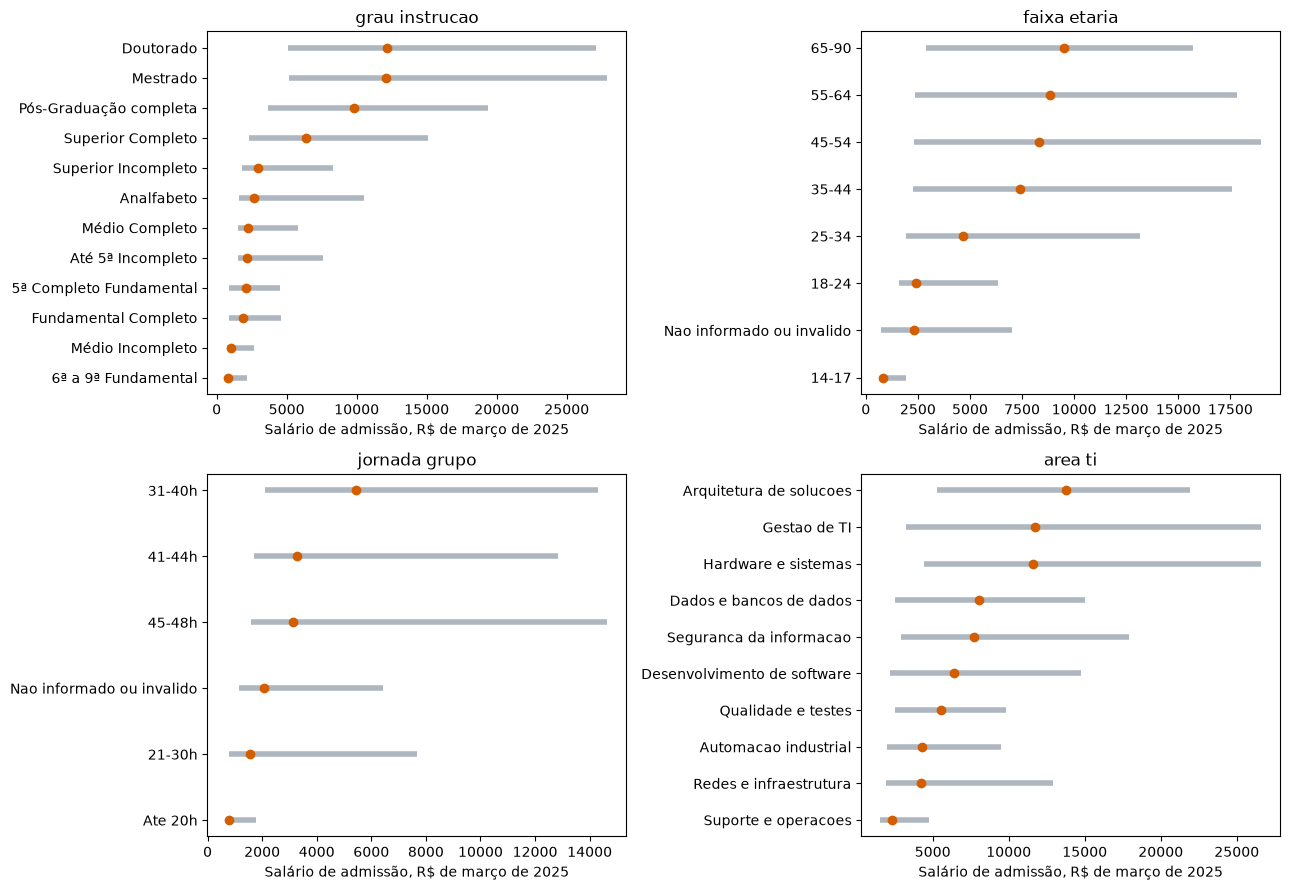

In [3]:
f = p['eda_associacoes_salariais']
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, field in zip(axes.flat, f.dimensao.unique()):
    s = f.loc[f.dimensao.eq(field)].sort_values('p50')
    ax.hlines(s.categoria, s.p10, s.p90, color='#AEB6C0', lw=4)
    ax.scatter(s.p50, s.categoria, color=colors[0], zorder=3)
    ax.set(title=field.replace('_', ' '), xlabel='Salário de admissão, R$ de março de 2025')
plt.tight_layout()
plt.show()

## P5–P8. Perfil e busca de emprego por edição
As edições são amostras voluntárias diferentes. Iniciantes têm até dois anos de experiência ou declararam não ter experiência. As faixas salariais são respostas ordenadas, não valores exatos. Categorias com menos de cinco respostas não são mostradas nas tabelas detalhadas.

,edicao,recorte,n_respostas,n_validas_busca,proporcao_busca
0,2025/2026,Brasil,3372,3123,0.3439
1,2025/2026,Pernambuco,78,67,0.3433
2,2024/2025,Brasil,5076,4734,0.3443
3,2024/2025,Pernambuco,120,105,0.5048


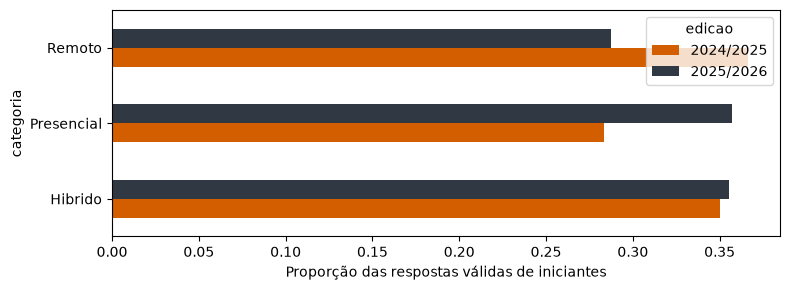

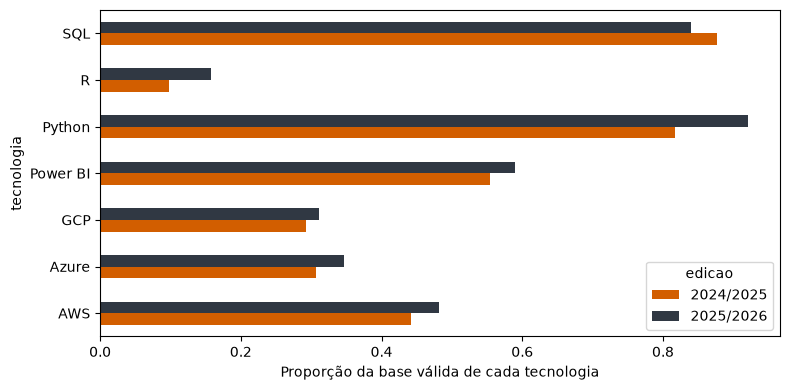

,edicao,dimensao,categoria,faixa,n,denominador
83,2025/2026,senioridade_declarada,Especialista/Staff+,de R$ 12.001/mês a R$ 16.000/mês,89,339
84,2025/2026,senioridade_declarada,Especialista/Staff+,de R$ 16.001/mês a R$ 20.000/mês,77,339
85,2025/2026,senioridade_declarada,Especialista/Staff+,de R$ 8.001/mês a R$ 12.000/mês,47,339
86,2025/2026,senioridade_declarada,Especialista/Staff+,de R$ 20.001/mês a R$ 25.000/mês,45,339
87,2025/2026,senioridade_declarada,Especialista/Staff+,de R$ 30.001/mês a R$ 40.000/mês,26,339
88,2025/2026,senioridade_declarada,Especialista/Staff+,de R$ 25.001/mês a R$ 30.000/mês,23,339
89,2025/2026,senioridade_declarada,Especialista/Staff+,Acima de R$ 40.001/mês,22,339
90,2025/2026,senioridade_declarada,Especialista/Staff+,de R$ 6.001/mês a R$ 8.000/mês,8,339
91,2025/2026,senioridade_declarada,Junior,de R$ 4.001/mês a R$ 6.000/mês,121,510
92,2025/2026,senioridade_declarada,Junior,de R$ 1.001/mês a R$ 2.000/mês,98,510


,edicao,dimensao,categoria,n,proporcao_busca
14,2025/2026,modelo_trabalho,Hibrido,1222,0.3028
15,2025/2026,modelo_trabalho,Presencial,650,0.4400
16,2025/2026,modelo_trabalho,Remoto,1251,0.3341
32,2024/2025,modelo_trabalho,Hibrido,1796,0.3385
33,2024/2025,modelo_trabalho,Presencial,783,0.4457
34,2024/2025,modelo_trabalho,Remoto,2155,0.3123


In [4]:
display(p['eda_comparacao_pesquisas'].round(4))
beginner = p['eda_iniciantes'].query("dimensao == 'modelo_trabalho'").copy()
beginner['proporcao'] = beginner.n / beginner.denominador
beginner.pivot(index='categoria', columns='edicao', values='proporcao').plot.barh(figsize=(8,3), color=colors[:2])
plt.xlabel('Proporção das respostas válidas de iniciantes')
plt.tight_layout()
plt.show()
tech = p['tecnologias'].query("geo == 'BR' and senioridade == 'Todos' and modelo == 'Todos'")
tech.pivot(index='tecnologia', columns='edicao', values='proporcao').plot.barh(figsize=(8,4), color=colors[:2])
plt.xlabel('Proporção da base válida de cada tecnologia')
plt.tight_layout()
plt.show()
display(p['eda_faixas_por_perfil'].query("dimensao == 'senioridade_declarada'").head(12))
display(p['eda_busca_por_perfil'].query("dimensao == 'modelo_trabalho'").round(4))

## Etapa 04. Regressão salarial
Seleção em out–dez/2025 e teste reservado em jan–set/2026. A referência é a mediana do treino. O gráfico de dispersão usa contagens agregadas; o corte visual não exclui eventos das métricas.

,modelo,n,mae
0,mediana,57287,4051.898
1,idade,57287,3770.565
2,multipla,57287,2831.007


,modelo,n,mae,rmse,r2,mediana_erro_absoluto,residuo_medio,previsoes_negativas
0,mediana,182057,3910.856,6778.372,-0.128,2070.725,2284.411,0
1,idade,182057,3712.237,5915.638,0.141,2555.096,-51.572,0
2,multipla,182057,2777.563,4783.204,0.438,1820.042,-8.108,3263


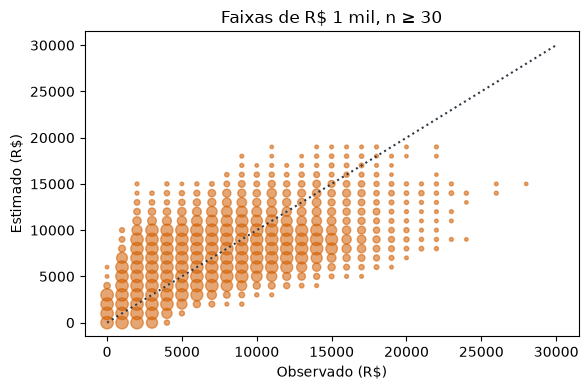

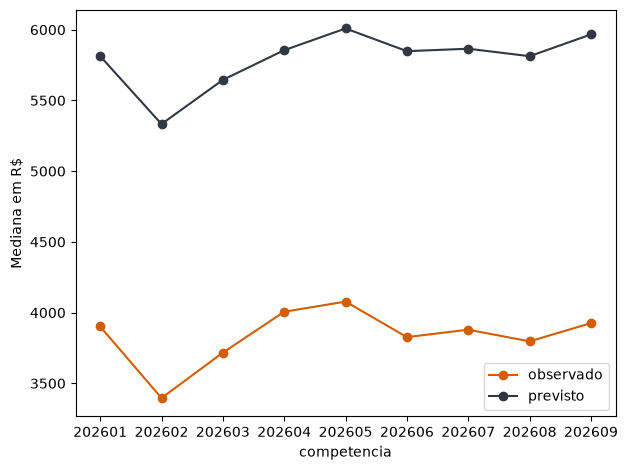

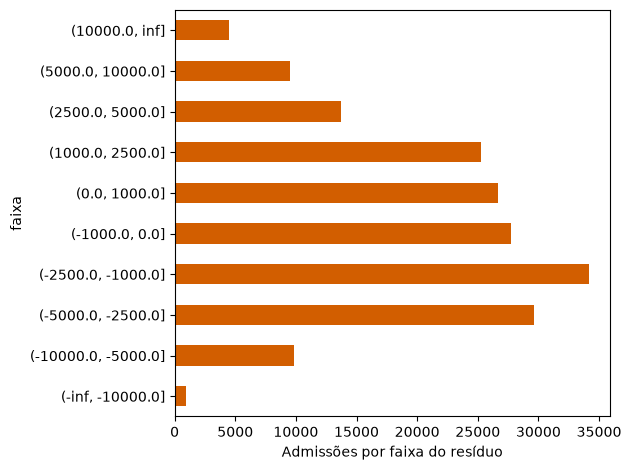

In [5]:
display(p['regressao_validacao'][['modelo', 'n', 'mae']].round(3))
display(p['regressao'].round(3))
scatter = p['regressao_dispersao']
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(scatter.observado, scatter.previsto, s=scatter.n.clip(upper=400)/5, alpha=.55, color=colors[0])
ax.plot([0,30000], [0,30000], color=colors[1], ls=':')
ax.set(xlabel='Observado (R$)', ylabel='Estimado (R$)', title='Faixas de R$ 1 mil, n ≥ 30')
plt.tight_layout()
plt.show()
p['regressao_mensal'].set_index('competencia')[['observado','previsto']].plot(color=colors[:2], marker='o')
plt.ylabel('Mediana em R$')
plt.tight_layout()
plt.show()
p['regressao_residuos'].set_index('faixa').n.plot.barh(color=colors[0])
plt.xlabel('Admissões por faixa do resíduo')
plt.tight_layout()
plt.show()

## Etapa 05. Classificação entre edições
O ajuste usa a edição 2024/2025; 2025/2026 é o teste. O alvo é a declaração de busca ativa, não uma saída futura. Acurácia isolada deve ser lida junto com recall e com a referência majoritária.

,modelo,ordem,ap_media
0,majoritaria,0,0.3443
1,logistica,1,0.4252
2,arvore,2,0.3991


,modelo,n,n_ativos,n_previstos_ativos,limiar,tn,fp,fn,tp,acuracia,precisao,recall,f1,roc_auc,average_precision,brier
0,majoritaria,3123,1074,0,0.5,2049,0,1074,0,0.6561,0.0000,0.0000,0.0000,0.5000,0.3439,0.2256
1,logistica,3123,1074,129,0.5,2001,48,993,81,0.6667,0.6279,0.0754,0.1347,0.5791,0.4355,0.2204
2,arvore,3123,1074,121,0.5,1995,54,1007,67,0.6603,0.5537,0.0624,0.1121,0.5660,0.4090,0.2211


,Estimado: não,Estimado: sim
Real: não,2001,48
Real: sim,993,81


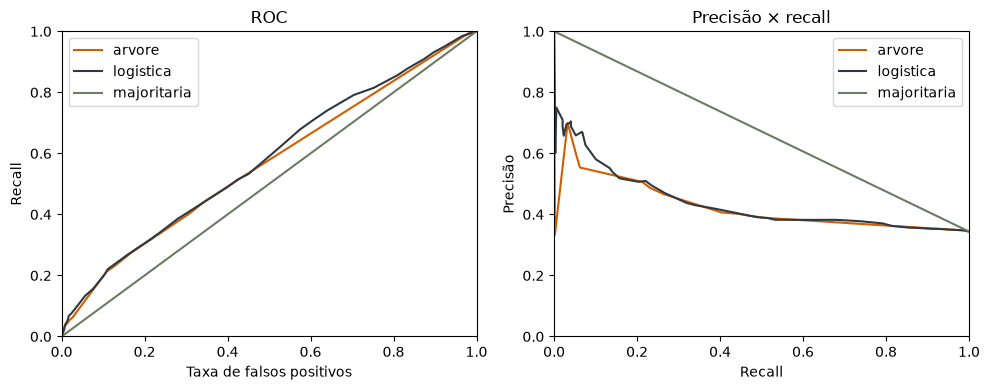

In [6]:
display(p['classificacao_validacao'].round(4))
display(p['classificacao'].round(4))
key = p['metadata']['modelos']['classificacao']['selecionado']
m = p['classificacao'].set_index('modelo').loc[key]
display(pd.DataFrame([[m.tn,m.fp],[m.fn,m.tp]], index=['Real: não','Real: sim'], columns=['Estimado: não','Estimado: sim']).astype(int))
fig, axes = plt.subplots(1,2,figsize=(10,4))
for (name, f), color in zip(p['classificacao_curvas'].groupby('modelo'), colors):
    axes[0].plot(f.fpr, f.recall, label=name, color=color)
    axes[1].plot(f.recall, f.precisao, label=name, color=color)
axes[0].set(xlabel='Taxa de falsos positivos', ylabel='Recall', title='ROC')
axes[1].set(xlabel='Recall', ylabel='Precisão', title='Precisão × recall')
for ax in axes:
    ax.set(xlim=(0,1), ylim=(0,1))
    ax.legend()
plt.tight_layout()
plt.show()

## Leitura final
As diferenças entre anos no CAGED comparam os mesmos nove meses. Mudanças na composição das respostas do State of Data não demonstram mudanças nas mesmas pessoas. O baixo recall e os erros salariais impedem o uso individual dos modelos.